# Perceptrón

## Introducción a las Redes Neuronales

### La Neurona Biológica

Para entender las redes neuronales artificiales, primero debemos entender su inspiración: **la neurona biológica**.

El cerebro humano contiene aproximadamente **86 mil millones de neuronas**, cada una conectada a miles de otras neuronas, formando una red de aproximadamente **100 billones de conexiones sinápticas**. Es esta red masiva la que nos permite pensar, aprender, recordar y tomar decisiones.

Una neurona biológica tiene cuatro componentes principales:

| Componente | Función |
|---|---|
| **Dendritas** | Reciben señales eléctricas de otras neuronas (entradas) |
| **Soma (cuerpo celular)** | Procesa las señales recibidas (suma/integración) |
| **Axón** | Transmite la señal de salida a otras neuronas |
| **Sinapsis** | Conexión entre el axón de una neurona y la dendrita de otra (pesos) |

El proceso funciona así:

1. Las **dendritas** reciben señales eléctricas de muchas otras neuronas.
2. Cada sinapsis tiene una **fuerza** diferente — algunas conexiones son más fuertes (excitatorias) y otras más débiles o inhibitorias.
3. El **soma** suma todas estas señales ponderadas.
4. Si la suma total supera un **umbral** (threshold), la neurona se "activa" y envía una señal eléctrica a través del **axón**.
5. Si no supera el umbral, la neurona permanece inactiva.

Este mecanismo de **"todo o nada"** es fundamental: la neurona **dispara o no dispara**. No hay señal parcial.

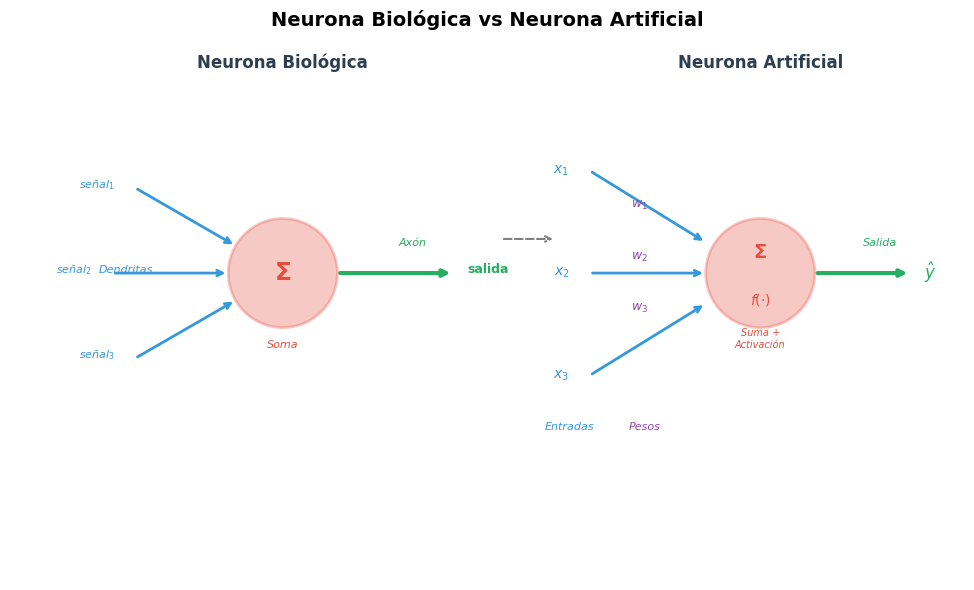

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

import warnings

warnings.filterwarnings("ignore", category=SyntaxWarning)

fig, ax = plt.subplots(1, 1, figsize=(12, 6))
ax.set_xlim(-1, 13)
ax.set_ylim(-2, 6)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Neurona Biológica vs Neurona Artificial', fontsize=14, fontweight='bold')

# --- Neurona biológica (izquierda) ---
ax.text(3, 5.5, 'Neurona Biológica', ha='center', fontsize=12, fontweight='bold', color='#2c3e50')

# Dendritas
for angle, label in zip([150, 180, 210], ['$señal_1$', '$señal_2$', '$señal_3$']):
    rad = np.radians(angle)
    x_end = 3 + 2.5 * np.cos(rad)
    y_end = 2.5 + 2.5 * np.sin(rad)
    ax.annotate('', xy=(3 + 0.8*np.cos(rad), 2.5 + 0.8*np.sin(rad)),
                xytext=(x_end, y_end),
                arrowprops=dict(arrowstyle='->', color='#3498db', lw=2))
    ax.text(x_end - 0.3, y_end, label, fontsize=8, color='#3498db', ha='right')

ax.text(0.3, 2.5, 'Dendritas', fontsize=8, color='#3498db', fontstyle='italic')

# Soma
soma = plt.Circle((3, 2.5), 0.8, color='#e74c3c', alpha=0.3, ec='#e74c3c', lw=2)
ax.add_patch(soma)
ax.text(3, 2.5, 'Σ', ha='center', va='center', fontsize=18, fontweight='bold', color='#e74c3c')
ax.text(3, 1.4, 'Soma', fontsize=8, color='#e74c3c', ha='center', fontstyle='italic')

# Axón
ax.annotate('', xy=(5.5, 2.5), xytext=(3.8, 2.5),
            arrowprops=dict(arrowstyle='->', color='#27ae60', lw=3))
ax.text(4.7, 2.9, 'Axón', fontsize=8, color='#27ae60', fontstyle='italic')
ax.text(5.7, 2.5, 'salida', fontsize=9, color='#27ae60', fontweight='bold')

# --- Neurona artificial (derecha) ---
ax.text(10, 5.5, 'Neurona Artificial', ha='center', fontsize=12, fontweight='bold', color='#2c3e50')

# Entradas con pesos
inputs_y = [4, 2.5, 1]
for i, (iy, label) in enumerate(zip(inputs_y, ['$x_1$', '$x_2$', '$x_3$'])):
    ax.annotate('', xy=(9.2, 2.5 + (iy-2.5)*0.3), xytext=(7.5, iy),
                arrowprops=dict(arrowstyle='->', color='#3498db', lw=2))
    ax.text(7.2, iy, label, fontsize=10, color='#3498db', ha='right', va='center')
    ax.text(8.1, (2.5 + iy)/2 + 0.2, f'$w_{i+1}$', fontsize=9, color='#8e44ad')

ax.text(7.2, 0.2, 'Entradas', fontsize=8, color='#3498db', ha='center', fontstyle='italic')
ax.text(8.3, 0.2, 'Pesos', fontsize=8, color='#8e44ad', ha='center', fontstyle='italic')

# Nodo de suma + activación
node = plt.Circle((10, 2.5), 0.8, color='#e74c3c', alpha=0.3, ec='#e74c3c', lw=2)
ax.add_patch(node)
ax.text(10, 2.8, 'Σ', ha='center', va='center', fontsize=14, fontweight='bold', color='#e74c3c')
ax.text(10, 2.1, '$f(·)$', ha='center', va='center', fontsize=10, color='#e74c3c')
ax.text(10, 1.4, 'Suma +\nActivación', fontsize=7, color='#e74c3c', ha='center', fontstyle='italic')

# Salida
ax.annotate('', xy=(12.2, 2.5), xytext=(10.8, 2.5),
            arrowprops=dict(arrowstyle='->', color='#27ae60', lw=3))
ax.text(12.4, 2.5, '$\hat{y}$', fontsize=12, color='#27ae60', fontweight='bold', va='center')
ax.text(11.5, 2.9, 'Salida', fontsize=8, color='#27ae60', fontstyle='italic')

# Flecha de correspondencia
ax.annotate('', xy=(7, 3), xytext=(6.2, 3),
            arrowprops=dict(arrowstyle='->', color='gray', lw=1.5, ls='--'))

plt.tight_layout()
plt.show()

### De la Biología a las Matemáticas: El Modelo de Neurona Artificial

En 1943, **Warren McCulloch** (neurofisiólogo) y **Walter Pitts** (lógico matemático) publicaron el artículo *"A Logical Calculus of the Ideas Immanent in Nervous Activity"*, donde propusieron el primer modelo matemático de una neurona artificial.

La analogía entre la neurona biológica y la artificial es directa:

| Neurona Biológica | Neurona Artificial | Símbolo |
|---|---|---|
| Señales de entrada (dendritas) | Valores de entrada | $x_1, x_2, \dots, x_n$ |
| Fuerza sináptica | Pesos | $w_1, w_2, \dots, w_n$ |
| Suma en el soma | Combinación lineal | $z = \sum_{i=1}^{n} w_i x_i + b$ |
| Umbral de activación | Función de activación | $f(z)$ |
| Señal de salida (axón) | Predicción | $\hat{y} = f(z)$ |
| Aprendizaje (plasticidad sináptica) | Actualización de pesos | $w_i \leftarrow w_i + \Delta w_i$ |

El modelo matemático de una neurona artificial es:

$$
\hat{y} = f\left(\sum_{i=1}^{n} w_i x_i + b\right) = f(\mathbf{w}^T \mathbf{x} + b)
$$

Donde:
- $\mathbf{x} = (x_1, x_2, \dots, x_n)^T$: vector de entradas
- $\mathbf{w} = (w_1, w_2, \dots, w_n)^T$: vector de pesos (lo que la neurona "aprende")
- $b$: sesgo (bias), equivalente al umbral de activación
- $f(\cdot)$: función de activación
- $\hat{y}$: salida de la neurona

### Funciones de Activación

La **función de activación** determina si la neurona se "activa" o no, y cómo transforma la señal. La elección de esta función es crucial y ha evolucionado significativamente a lo largo de la historia de las redes neuronales.

**¿Por qué necesitamos funciones de activación?**

Sin una función de activación, la neurona solo calcularía una combinación lineal: $\hat{y} = \mathbf{w}^T\mathbf{x} + b$. Esto tiene un problema fundamental: **la composición de funciones lineales es otra función lineal**. Es decir, apilar muchas capas lineales no agrega capacidad expresiva:

$$
f_2(f_1(\mathbf{x})) = \mathbf{W}_2(\mathbf{W}_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = \underbrace{\mathbf{W}_2\mathbf{W}_1}_{\mathbf{W}'}\mathbf{x} + \underbrace{\mathbf{W}_2\mathbf{b}_1 + \mathbf{b}_2}_{\mathbf{b}'} = \mathbf{W}'\mathbf{x} + \mathbf{b}'
$$

Las funciones de activación **no lineales** rompen esta limitación y permiten que las redes neuronales aprendan relaciones complejas.

Las funciones de activación más importantes son:

| Función | Fórmula | Rango | Uso principal |
|---|---|---|---|
| **Escalón (Step)** | $f(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$ | $\{0, 1\}$ | Perceptrón original |
| **Sigmoide** | $f(z) = \frac{1}{1 + e^{-z}}$ | $(0, 1)$ | Clasificación binaria |
| **Tanh** | $f(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$ | $(-1, 1)$ | Capas ocultas (centrada en 0) |
| **ReLU** | $f(z) = \max(0, z)$ | $[0, \infty)$ | Redes profundas (más usada) |
| **Leaky ReLU** | $f(z) = \max(\alpha z, z)$ | $(-\infty, \infty)$ | Evita "neuronas muertas" |
| **Softmax** | $f(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$ | $(0, 1)$, suma = 1 | Clasificación multiclase |

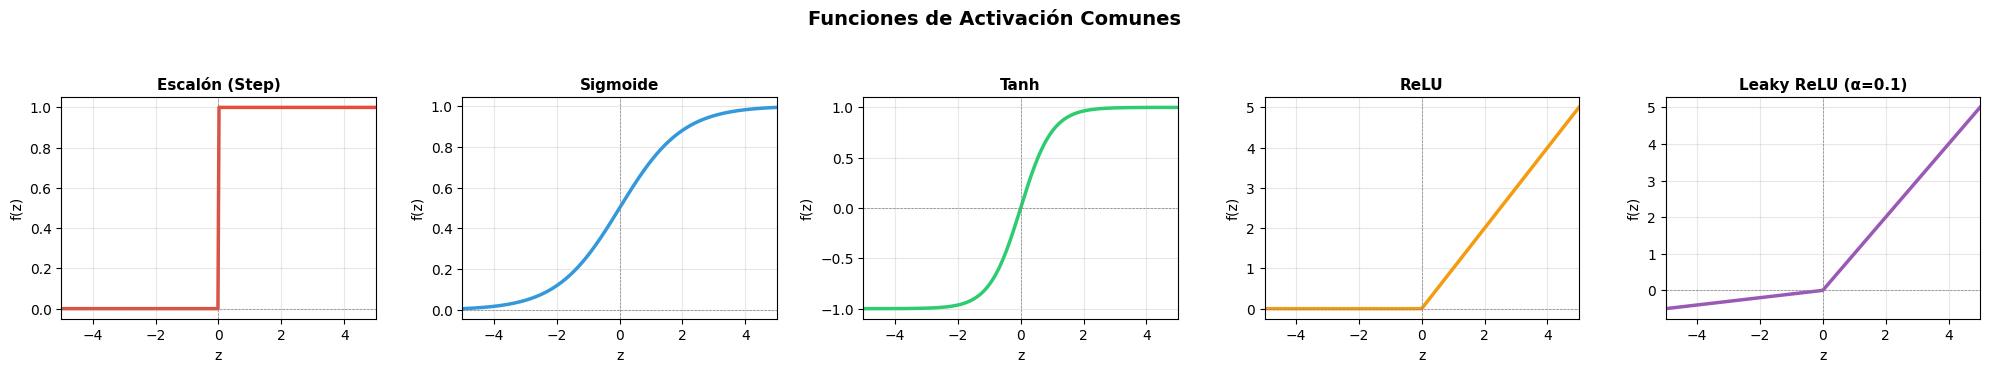

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-5, 5, 300)

# Funciones de activación
step = np.where(z >= 0, 1, 0)
sigmoid = 1 / (1 + np.exp(-z))
tanh = np.tanh(z)
relu = np.maximum(0, z)
leaky_relu = np.where(z > 0, z, 0.1 * z)

activations = [
    ('Escalón (Step)', step, '#e74c3c'),
    ('Sigmoide', sigmoid, '#3498db'),
    ('Tanh', tanh, '#2ecc71'),
    ('ReLU', relu, '#f39c12'),
    ('Leaky ReLU (α=0.1)', leaky_relu, '#9b59b6'),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, (name, func, color) in zip(axes, activations):
    ax.plot(z, func, color=color, linewidth=2.5)
    ax.axhline(y=0, color='gray', linewidth=0.5, linestyle='--')
    ax.axvline(x=0, color='gray', linewidth=0.5, linestyle='--')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_xlabel('z', fontsize=10)
    ax.set_ylabel('f(z)', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-5, 5)

plt.suptitle('Funciones de Activación Comunes', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

### Arquitectura de Redes Neuronales

Una sola neurona artificial tiene capacidad limitada — solo puede aprender **fronteras de decisión lineales**. El verdadero poder emerge cuando conectamos muchas neuronas en **capas**.

Una red neuronal típica tiene tres tipos de capas:

1. **Capa de entrada** (*Input Layer*): Recibe los datos crudos. Tiene una neurona por cada feature del dataset. No realiza cálculos.

2. **Capas ocultas** (*Hidden Layers*): Realizan las transformaciones intermedias. Cada neurona en una capa oculta:
   - Recibe todas las salidas de la capa anterior
   - Calcula su combinación lineal ponderada
   - Aplica su función de activación
   - Envía su salida a todas las neuronas de la siguiente capa

3. **Capa de salida** (*Output Layer*): Produce el resultado final. Su estructura depende del problema:
   - **Regresión**: 1 neurona sin activación (o lineal)
   - **Clasificación binaria**: 1 neurona con sigmoide
   - **Clasificación multiclase**: $C$ neuronas con softmax

**Notación formal** para una red de $L$ capas:

$$
\mathbf{a}^{[0]} = \mathbf{x} \quad \text{(entrada)}
$$

$$
\mathbf{z}^{[l]} = \mathbf{W}^{[l]} \mathbf{a}^{[l-1]} + \mathbf{b}^{[l]} \quad \text{para } l = 1, 2, \dots, L
$$

$$
\mathbf{a}^{[l]} = f^{[l]}(\mathbf{z}^{[l]}) \quad \text{para } l = 1, 2, \dots, L
$$

$$
\hat{\mathbf{y}} = \mathbf{a}^{[L]} \quad \text{(salida)}
$$

Donde:
- $\mathbf{W}^{[l]}$: matriz de pesos de la capa $l$ (dimensión: neuronas en capa $l$ × neuronas en capa $l-1$)
- $\mathbf{b}^{[l]}$: vector de sesgos de la capa $l$
- $\mathbf{z}^{[l]}$: pre-activación de la capa $l$
- $\mathbf{a}^{[l]}$: activación (salida) de la capa $l$
- $f^{[l]}$: función de activación de la capa $l$

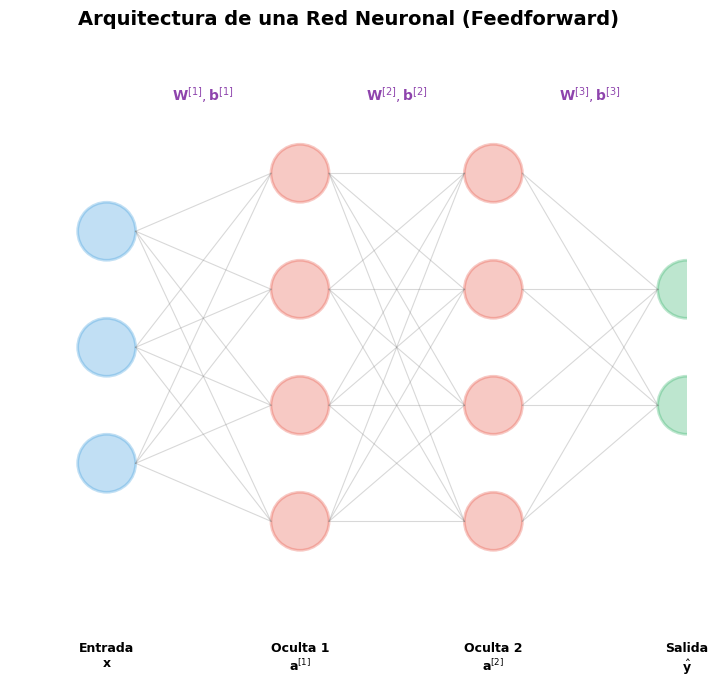

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, ax = plt.subplots(1, 1, figsize=(10, 7))
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(-0.5, 6)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Arquitectura de una Red Neuronal (Feedforward)', fontsize=14, fontweight='bold')

# Definir capas: (x_pos, n_neuronas, nombre, color)
layers = [
    (0.5, 3, 'Entrada\n$\mathbf{x}$', '#3498db'),
    (2.5, 4, 'Oculta 1\n$\mathbf{a}^{[1]}$', '#e74c3c'),
    (4.5, 4, 'Oculta 2\n$\mathbf{a}^{[2]}$', '#e74c3c'),
    (6.5, 2, 'Salida\n$\hat{\mathbf{y}}$', '#27ae60'),
]

neuron_positions = []
for x, n, name, color in layers:
    positions = []
    total_height = (n - 1) * 1.2
    start_y = 2.75 - total_height / 2
    for i in range(n):
        y = start_y + i * 1.2
        circle = plt.Circle((x, y), 0.3, color=color, alpha=0.3, ec=color, lw=2)
        ax.add_patch(circle)
        positions.append((x, y))
    neuron_positions.append(positions)
    ax.text(x, -0.3, name, ha='center', va='top', fontsize=9, fontweight='bold')

# Dibujar conexiones
for l in range(len(neuron_positions) - 1):
    for (x1, y1) in neuron_positions[l]:
        for (x2, y2) in neuron_positions[l + 1]:
            ax.plot([x1 + 0.3, x2 - 0.3], [y1, y2], 'gray', alpha=0.3, lw=0.8)

# Etiquetas de pesos
ax.text(1.5, 5.3, '$\mathbf{W}^{[1]}, \mathbf{b}^{[1]}$', ha='center', fontsize=10, color='#8e44ad')
ax.text(3.5, 5.3, '$\mathbf{W}^{[2]}, \mathbf{b}^{[2]}$', ha='center', fontsize=10, color='#8e44ad')
ax.text(5.5, 5.3, '$\mathbf{W}^{[3]}, \mathbf{b}^{[3]}$', ha='center', fontsize=10, color='#8e44ad')

plt.tight_layout()
plt.show()

### Aprendizaje en Redes Neuronales

¿Cómo "aprende" una red neuronal? El proceso tiene tres etapas fundamentales:

#### 1. Forward Propagation (Propagación hacia adelante)

Los datos de entrada se propagan capa por capa hasta producir una predicción $\hat{y}$. Es simplemente evaluar la función compuesta de la red:

$$
\mathbf{x} \xrightarrow{\mathbf{W}^{[1]}, f^{[1]}} \mathbf{a}^{[1]} \xrightarrow{\mathbf{W}^{[2]}, f^{[2]}} \mathbf{a}^{[2]} \xrightarrow{} \cdots \xrightarrow{\mathbf{W}^{[L]}, f^{[L]}} \hat{\mathbf{y}}
$$

#### 2. Función de Pérdida (Loss Function)

Necesitamos medir **qué tan mal** está la predicción. La función de pérdida $\mathscr{L}(\hat{y}, y)$ cuantifica el error. Ejemplos comunes:

- **Error Cuadrático Medio** (regresión): $\mathscr{L} = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2$

- **Entropía Cruzada Binaria** (clasificación binaria): $\mathscr{L} = -\frac{1}{n}\sum_{i=1}^{n}[y_i \log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)]$

- **Entropía Cruzada Categórica** (multiclase): $\mathscr{L} = -\frac{1}{n}\sum_{i=1}^{n}\sum_{c=1}^{C}y_{i,c}\log(\hat{y}_{i,c})$

#### 3. Backpropagation (Retropropagación)

El algoritmo clave que permite entrenar redes profundas. Fue popularizado por **Rumelhart, Hinton y Williams** en 1986.

La idea es usar la **regla de la cadena** del cálculo para propagar el error desde la salida hacia atrás, calculando cuánto contribuyó cada peso al error total:

$$
\frac{\partial \mathscr{L}}{\partial w_{ij}^{[l]}} = \frac{\partial \mathscr{L}}{\partial a_j^{[L]}} \cdot \frac{\partial a_j^{[L]}}{\partial z_j^{[L]}} \cdot \frac{\partial z_j^{[L]}}{\partial a_k^{[L-1]}} \cdots \frac{\partial z^{[l]}}{\partial w_{ij}^{[l]}}
$$

Con estos gradientes, actualizamos los pesos usando **Descenso de Gradiente**:

$$
w_{ij}^{[l]} \leftarrow w_{ij}^{[l]} - \eta \frac{\partial \mathscr{L}}{\partial w_{ij}^{[l]}}
$$

Donde $\eta$ es la **tasa de aprendizaje** (learning rate).

Este proceso se repite miles de veces hasta que la red converge a un buen conjunto de pesos.

### Breve Historia de las Redes Neuronales

Las redes neuronales han tenido una historia fascinante de auge, caída y resurgimiento:

| Año | Evento | Impacto |
|---|---|---|
| **1943** | McCulloch & Pitts: modelo de neurona artificial | Primera formalización matemática |
| **1949** | Donald Hebb: *The Organization of Behavior* | "Las neuronas que disparan juntas, se conectan juntas" (regla de Hebb) |
| **1958** | Frank Rosenblatt: **Perceptrón** | Primera red neuronal capaz de aprender de los datos |
| **1969** | Minsky & Papert: *Perceptrons* (libro) | Demostraron que el Perceptrón no puede resolver XOR → **primer invierno de la IA** |
| **1986** | Rumelhart, Hinton & Williams: Backpropagation | Permitió entrenar redes multicapa → resurgimiento |
| **1989** | Yann LeCun: Redes Convolucionales (CNN) | Reconocimiento de dígitos escritos a mano |
| **1991** | Hochreiter: problema del gradiente desvaneciente | **Segundo invierno** — dificultad para entrenar redes profundas |
| **1997** | Hochreiter & Schmidhuber: LSTM | Redes recurrentes con memoria a largo plazo |
| **2006** | Geoffrey Hinton: Deep Belief Networks | Renacimiento del Deep Learning |
| **2012** | AlexNet (Krizhevsky et al.) | CNN gana ImageNet por amplio margen → **revolución del Deep Learning** |
| **2014** | GANs (Goodfellow et al.) | Redes generativas adversarias |
| **2017** | Transformer (Vaswani et al.) | "Attention Is All You Need" → base de GPT, BERT |
| **2020+** | LLMs (GPT-3, ChatGPT, etc.) | Modelos de lenguaje masivos cambian la IA |

El **Perceptrón** es el **primer eslabón** de esta cadena. Aunque es el modelo más simple de red neuronal (una sola neurona), entenderlo a fondo es fundamental para comprender todo lo que vino después.

### Tipos de Redes Neuronales

A partir de la neurona artificial básica, se han desarrollado diversas arquitecturas especializadas:

**1. Perceptrón / Red Feedforward (MLP)**
- La forma más básica: la información fluye en una sola dirección (entrada → salida)
- **Perceptrón Simple**: una sola neurona (lo que implementaremos hoy)
- **Perceptrón Multicapa (MLP)**: múltiples capas de neuronas completamente conectadas
- Uso: clasificación general, regresión, datos tabulares

**2. Redes Convolucionales (CNN)**
- Usan filtros (kernels) que se deslizan sobre los datos detectando patrones locales
- Explotan la estructura espacial de los datos
- Uso: imágenes, video, señales 1D

**3. Redes Recurrentes (RNN, LSTM, GRU)**
- Tienen conexiones cíclicas que les permiten "recordar" información previa
- Procesan secuencias de longitud variable
- Uso: series temporales, texto, audio

**4. Transformers**
- Basados en el mecanismo de **atención** (attention)
- Procesan toda la secuencia en paralelo (a diferencia de las RNN)
- Uso: NLP (GPT, BERT), visión (ViT), multimodal

**5. Autoencoders**
- Aprenden una representación comprimida de los datos (encoder → bottleneck → decoder)
- Uso: reducción de dimensionalidad, generación de datos, detección de anomalías

**6. Redes Generativas Adversarias (GANs)**
- Dos redes compiten: un generador crea datos falsos y un discriminador intenta detectarlos
- Uso: generación de imágenes, aumento de datos, super-resolución

Todos estos modelos comparten los mismos principios fundamentales: **neuronas artificiales + pesos aprendibles + funciones de activación + backpropagation**. El Perceptrón es donde todo comienza.

### El Teorema de Aproximación Universal

Uno de los resultados teóricos más importantes de las redes neuronales es el **Teorema de Aproximación Universal** (Cybenko, 1989; Hornik, 1991):

> Una red neuronal feedforward con **una sola capa oculta** que contenga un número suficiente de neuronas con funciones de activación no lineales puede **aproximar cualquier función continua** $f: \mathbb{R}^n \to \mathbb{R}$ con precisión arbitraria en un subconjunto compacto.

Formalmente: para cualquier función continua $f$ y cualquier $\epsilon > 0$, existe una red $g$ con una capa oculta tal que:

$$
|f(\mathbf{x}) - g(\mathbf{x})| < \epsilon \quad \forall \mathbf{x} \in K
$$

**¿Qué significa esto?**
- Las redes neuronales son **aproximadores universales**: pueden representar cualquier relación entrada-salida.
- El teorema es de **existencia**: dice que la red existe, pero **no dice cómo encontrarla** (no garantiza que el entrenamiento converja).
- En la práctica, redes **profundas** (muchas capas) son más eficientes que redes anchas (una capa con miles de neuronas).

**¿Por qué empezar con el Perceptrón si es tan simple?**

Porque el Perceptrón es el **bloque fundamental**. Entender cómo una sola neurona aprende a clasificar nos da la base para entender cómo redes de miles de millones de neuronas (como los modelos de lenguaje modernos) aprenden a realizar tareas complejas.

---

## ¿Cuál es el objetivo del Perceptrón?

El **Perceptrón** fue propuesto por **Frank Rosenblatt** en 1958 y es el modelo más simple de red neuronal artificial: **una sola neurona** que aprende a clasificar datos en dos categorías.

El objetivo del Perceptrón es encontrar un **hiperplano** (en 2D, una línea recta) que separe los datos de dos clases diferentes. Es un **clasificador binario lineal**.

Formalmente, dado un vector de entrada $\mathbf{x} = (x_1, x_2, \dots, x_n)$, el Perceptrón calcula:

$$
\hat{y} = f(\mathbf{w}^T \mathbf{x} + b) = f\left(\sum_{i=1}^{n} w_i x_i + b\right)
$$

Donde $f$ es la **función escalón unitario** (unit step function):

$$
f(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}
$$

Es decir:
- Calcula la **suma ponderada** de las entradas.
- Si la suma es $\geq 0$, predice **clase 1**.
- Si la suma es $< 0$, predice **clase 0**.

La frontera de decisión es el conjunto de puntos donde $\mathbf{w}^T \mathbf{x} + b = 0$, que en 2D es una **línea recta**:

$$
w_1 x_1 + w_2 x_2 + b = 0 \quad \Rightarrow \quad x_2 = -\frac{w_1}{w_2} x_1 - \frac{b}{w_2}
$$

**Supongamos un conjunto de datos simple**

Tomemos estos puntos en 2D que representan dos clases:

| $x_1$ | $x_2$ | Clase |
|-------|-------|-------|
| 0     | 0     | 0     |
| 0     | 1     | 0     |
| 1     | 0     | 0     |
| 3     | 3     | 1     |
| 3     | 4     | 1     |
| 4     | 3     | 1     |

Estos datos son **linealmente separables**: podemos trazar una línea recta que separe perfectamente las dos clases. El Perceptrón puede aprender esta línea.

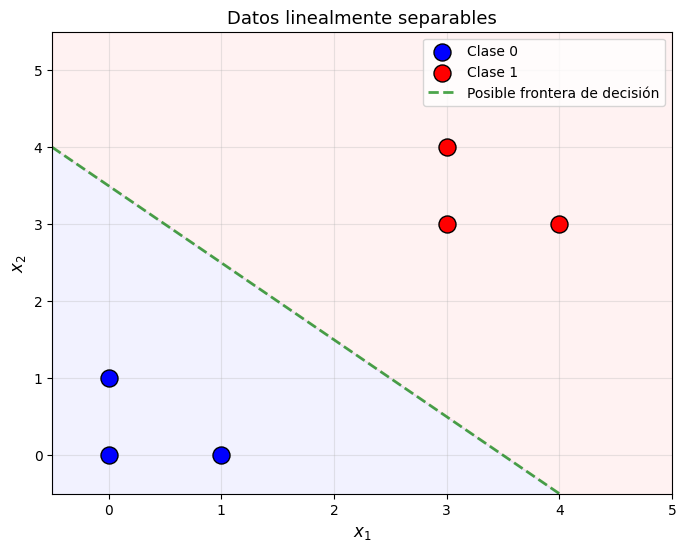

El Perceptrón debe aprender los pesos w₁, w₂ y el sesgo b
para trazar una línea que separe las dos clases.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Datos de entrenamiento
X = np.array([[0, 0], [0, 1], [1, 0], [3, 3], [3, 4], [4, 3]])
y = np.array([0, 0, 0, 1, 1, 1])

plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='blue', label='Clase 0', s=150, edgecolors='k', zorder=5)
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='red', label='Clase 1', s=150, edgecolors='k', zorder=5)

# Línea separadora "ideal" (ejemplo)
x_line = np.linspace(-0.5, 5, 100)
y_line = -x_line + 3.5  # una posible línea separadora
plt.plot(x_line, y_line, 'g--', linewidth=2, label='Posible frontera de decisión', alpha=0.7)
plt.fill_between(x_line, y_line, 5.5, alpha=0.05, color='red')
plt.fill_between(x_line, y_line, -1.5, alpha=0.05, color='blue')

plt.xlabel('$x_1$', fontsize=12)
plt.ylabel('$x_2$', fontsize=12)
plt.title('Datos linealmente separables', fontsize=13)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.xlim(-0.5, 5)
plt.ylim(-0.5, 5.5)
plt.show()

print("El Perceptrón debe aprender los pesos w₁, w₂ y el sesgo b")
print("para trazar una línea que separe las dos clases.")

## ¿Cómo aprende el Perceptrón?

A diferencia de algoritmos como la regresión logística que minimizan una función de pérdida diferenciable, el Perceptrón tiene una **regla de aprendizaje** simple e intuitiva basada en **corregir errores**:

- Si la predicción es **correcta** → no hagas nada.
- Si la predicción es **incorrecta** → ajusta los pesos en la dirección que corrige el error.

Pero... **¿cómo exactamente se ajustan los pesos?** Para entenderlo, necesitamos la demostración matemática completa.

## Demostración Matemática

### Paso 1: Modelo del Perceptrón

El Perceptrón calcula la salida en dos etapas:

**Etapa 1 — Combinación lineal:**

$$
z = \mathbf{w}^T \mathbf{x} + b = \sum_{i=1}^{n} w_i x_i + b
$$

**Etapa 2 — Función de activación (escalón unitario):**

$$
\hat{y} = f(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}
$$

Geométricamente, el Perceptrón divide el espacio en dos regiones:
- **Región positiva** ($z \geq 0$): predicción = 1
- **Región negativa** ($z < 0$): predicción = 0

La frontera entre ambas regiones es el **hiperplano** $\mathbf{w}^T \mathbf{x} + b = 0$.

El vector de pesos $\mathbf{w}$ es **perpendicular** a este hiperplano y apunta hacia la región de la clase 1.

### Paso 2: Regla de Actualización del Perceptrón

La regla de aprendizaje del Perceptrón actualiza los pesos **solo cuando hay un error** en la predicción. Para cada muestra $(\mathbf{x}_i, y_i)$:

1. Calcular la predicción: $\hat{y}_i = f(\mathbf{w}^T \mathbf{x}_i + b)$
2. Calcular el error: $e_i = y_i - \hat{y}_i$
3. Actualizar los pesos:

$$
\mathbf{w} \leftarrow \mathbf{w} + \eta \cdot (y_i - \hat{y}_i) \cdot \mathbf{x}_i
$$

$$
b \leftarrow b + \eta \cdot (y_i - \hat{y}_i)
$$

Donde $\eta$ es la **tasa de aprendizaje** (learning rate), un valor pequeño como 0.01.

**¿Por qué funciona esta regla?** Analicemos los tres casos posibles:

**Caso 1: Predicción correcta** ($\hat{y}_i = y_i$)

$$
y_i - \hat{y}_i = 0 \quad \Rightarrow \quad \Delta \mathbf{w} = \eta \cdot 0 \cdot \mathbf{x}_i = \mathbf{0}
$$

No se actualiza nada. ✓

**Caso 2: Falso negativo** ($y_i = 1, \hat{y}_i = 0$)

$$
y_i - \hat{y}_i = 1 \quad \Rightarrow \quad \mathbf{w} \leftarrow \mathbf{w} + \eta \cdot \mathbf{x}_i
$$

El peso se mueve **hacia** $\mathbf{x}_i$, haciendo que $\mathbf{w}^T \mathbf{x}_i$ **aumente**. Esto empuja la salida $z$ hacia valores positivos, corrigiendo la predicción hacia 1. ✓

**Caso 3: Falso positivo** ($y_i = 0, \hat{y}_i = 1$)

$$
y_i - \hat{y}_i = -1 \quad \Rightarrow \quad \mathbf{w} \leftarrow \mathbf{w} - \eta \cdot \mathbf{x}_i
$$

El peso se mueve **alejándose** de $\mathbf{x}_i$, haciendo que $\mathbf{w}^T \mathbf{x}_i$ **disminuya**. Esto empuja la salida $z$ hacia valores negativos, corrigiendo la predicción hacia 0. ✓

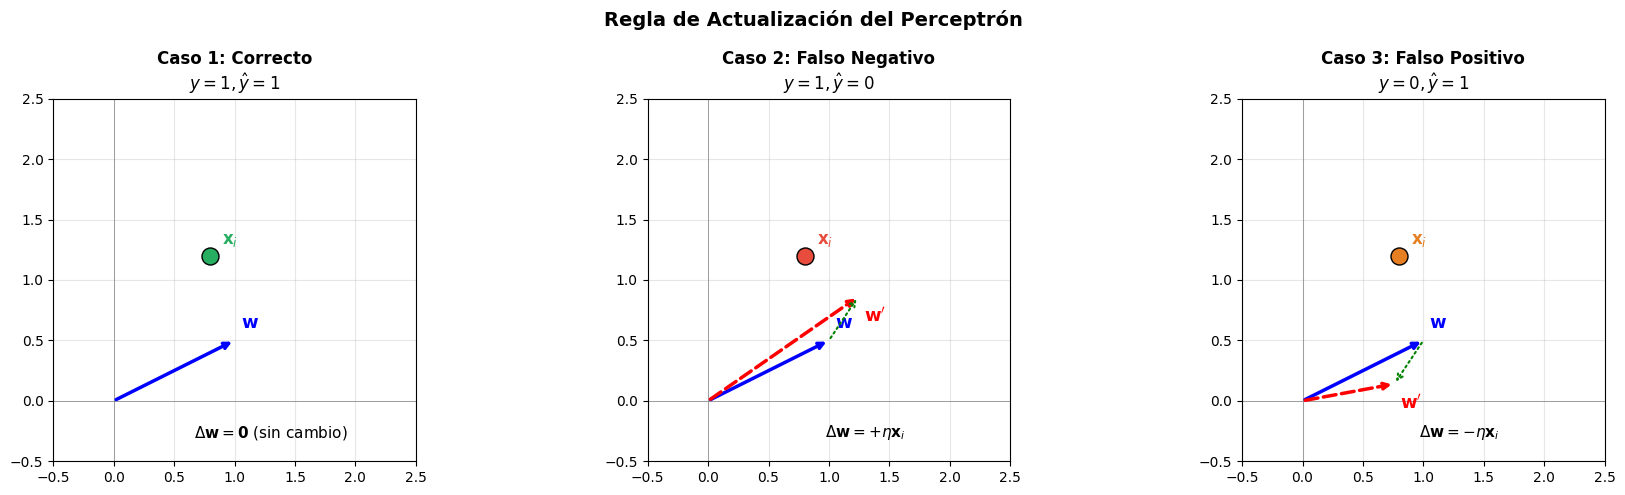

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Visualizar los tres casos de actualización
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cases = [
    ('Caso 1: Correcto\n$y=1, \hat{y}=1$', 1, 1, '#27ae60'),
    ('Caso 2: Falso Negativo\n$y=1, \hat{y}=0$', 1, 0, '#e74c3c'),
    ('Caso 3: Falso Positivo\n$y=0, \hat{y}=1$', 0, 1, '#e67e22'),
]

w = np.array([1.0, 0.5])  # pesos actuales
x_i = np.array([0.8, 1.2])  # punto de ejemplo
lr = 0.3

for ax, (title, y_true, y_pred, color) in zip(axes, cases):
    update = lr * (y_true - y_pred)
    w_new = w + update * x_i

    ax.set_xlim(-0.5, 2.5)
    ax.set_ylim(-0.5, 2.5)
    ax.set_aspect('equal')

    # Dibujar w original
    ax.annotate('', xy=(w[0], w[1]), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='blue', lw=2.5))
    ax.text(w[0]+0.05, w[1]+0.1, '$\mathbf{w}$', fontsize=13, color='blue', fontweight='bold')

    # Dibujar punto
    ax.scatter(x_i[0], x_i[1], color=color, s=150, edgecolors='k', zorder=5)
    ax.text(x_i[0]+0.1, x_i[1]+0.1, '$\mathbf{x}_i$', fontsize=12, color=color)

    if update != 0:
        # Dibujar w nuevo
        ax.annotate('', xy=(w_new[0], w_new[1]), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color='red', lw=2.5, ls='--'))
        ax.text(w_new[0]+0.05, w_new[1]-0.2, "$\mathbf{w}'$", fontsize=13, color='red', fontweight='bold')

        # Flecha de actualización
        ax.annotate('', xy=(w_new[0], w_new[1]), xytext=(w[0], w[1]),
                    arrowprops=dict(arrowstyle='->', color='green', lw=1.5, ls=':'))
        direction = '+' if update > 0 else '-'
        ax.text(1.3, -0.3, f'$\Delta\mathbf{{w}} = {direction}\eta\mathbf{{x}}_i$', fontsize=11, ha='center')
    else:
        ax.text(1.3, -0.3, '$\Delta\mathbf{w} = \mathbf{0}$ (sin cambio)', fontsize=11, ha='center')

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='gray', lw=0.5)
    ax.axvline(x=0, color='gray', lw=0.5)

plt.suptitle('Regla de Actualización del Perceptrón', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Paso 3: Convergencia del Perceptrón

Una pregunta natural es: **¿siempre converge el Perceptrón?**

La respuesta está en el **Teorema de Convergencia del Perceptrón** (Novikov, 1962; Block, 1962):

> Si los datos de entrenamiento son **linealmente separables**, el algoritmo del Perceptrón **convergerá** en un número finito de pasos y encontrará un hiperplano que separa perfectamente las clases.

**Demostración (sketch):**

Sea $\mathbf{w}^*$ un vector de pesos que separa perfectamente los datos con margen $\gamma > 0$, es decir:

$$
y_i(\mathbf{w}^{*T} \mathbf{x}_i) \geq \gamma \quad \forall i
$$

(donde convertimos las etiquetas a $\{-1, +1\}$)

Sea $R = \max_i \|\mathbf{x}_i\|$ el radio máximo de los datos.

Entonces se puede demostrar que el número máximo de errores (actualizaciones) $T$ está acotado por:

$$
T \leq \left(\frac{R \cdot \|\mathbf{w}^*\|}{\gamma}\right)^2
$$

**¿Qué significa esto?**
- Si los datos **son** linealmente separables → el Perceptrón **siempre** encuentra una solución.
- Si los datos **no son** linealmente separables → el Perceptrón **nunca** converge (oscila indefinidamente).
- Cuanto mayor es el **margen** $\gamma$ entre las clases, **más rápido** converge.
- Cuanto mayor es el **radio** $R$ de los datos, **más lento** converge.

Esta es la mayor **limitación** del Perceptrón: solo funciona con datos linealmente separables.

### Paso 4: El problema XOR — La limitación del Perceptrón

En 1969, Marvin Minsky y Seymour Papert publicaron su famoso libro *Perceptrons* donde demostraron que el Perceptrón **no puede resolver el problema XOR**.

| $x_1$ | $x_2$ | XOR |
|-------|-------|-----|
| 0     | 0     | 0   |
| 0     | 1     | 1   |
| 1     | 0     | 1   |
| 1     | 1     | 0   |

**¿Por qué no puede?** Porque los datos XOR **no son linealmente separables**: no existe ninguna línea recta que separe los 1s de los 0s.

**Prueba por contradicción:**

Supongamos que existe un hiperplano $w_1 x_1 + w_2 x_2 + b = 0$ que resuelve XOR. Entonces:

1. $(0,0) \to 0$: $w_1(0) + w_2(0) + b < 0 \Rightarrow b < 0$
2. $(0,1) \to 1$: $w_1(0) + w_2(1) + b \geq 0 \Rightarrow w_2 + b \geq 0 \Rightarrow w_2 \geq -b > 0$
3. $(1,0) \to 1$: $w_1(1) + w_2(0) + b \geq 0 \Rightarrow w_1 + b \geq 0 \Rightarrow w_1 \geq -b > 0$
4. $(1,1) \to 0$: $w_1(1) + w_2(1) + b < 0 \Rightarrow w_1 + w_2 + b < 0$

De (2) y (3): $w_1 + w_2 \geq -2b > 0$

Pero de (4): $w_1 + w_2 < -b$

Combinando: $-2b \leq w_1 + w_2 < -b \Rightarrow -2b < -b \Rightarrow -b < 0 \Rightarrow b > 0$

Esto contradice $b < 0$ de la condición (1). **Contradicción.** ∎

Esta limitación provocó el "primer invierno de la IA". La solución llegó décadas después con las **redes multicapa** y el **backpropagation**.

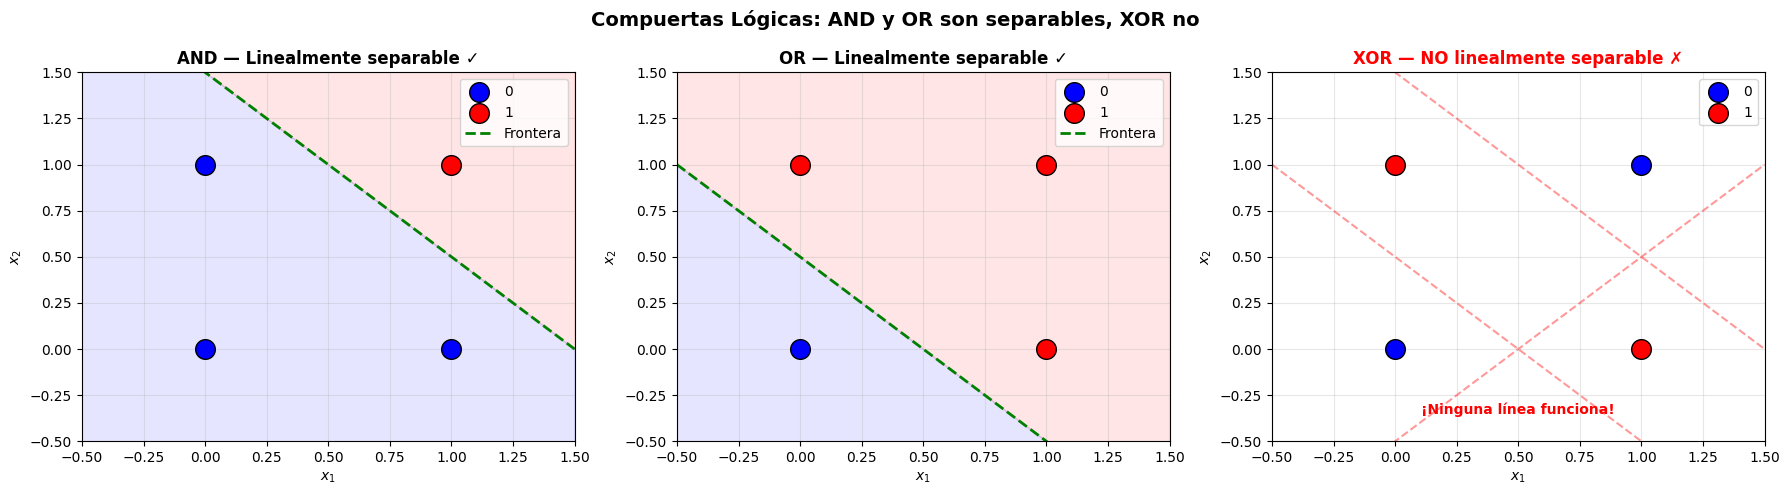

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Visualizar por qué XOR no es linealmente separable
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# AND (linealmente separable)
X_and = np.array([[0,0],[0,1],[1,0],[1,1]])
y_and = np.array([0, 0, 0, 1])

axes[0].scatter(X_and[y_and==0][:,0], X_and[y_and==0][:,1], c='blue', s=200, edgecolors='k', zorder=5, label='0')
axes[0].scatter(X_and[y_and==1][:,0], X_and[y_and==1][:,1], c='red', s=200, edgecolors='k', zorder=5, label='1')
x_line = np.linspace(-0.5, 1.5, 100)
axes[0].plot(x_line, -x_line + 1.5, 'g--', lw=2, label='Frontera')
axes[0].fill_between(x_line, -x_line+1.5, 2, alpha=0.1, color='red')
axes[0].fill_between(x_line, -x_line+1.5, -1, alpha=0.1, color='blue')
axes[0].set_title('AND — Linealmente separable ✓', fontsize=12, fontweight='bold')
axes[0].set_xlim(-0.5, 1.5)
axes[0].set_ylim(-0.5, 1.5)
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')

# OR (linealmente separable)
y_or = np.array([0, 1, 1, 1])
axes[1].scatter(X_and[y_or==0][:,0], X_and[y_or==0][:,1], c='blue', s=200, edgecolors='k', zorder=5, label='0')
axes[1].scatter(X_and[y_or==1][:,0], X_and[y_or==1][:,1], c='red', s=200, edgecolors='k', zorder=5, label='1')
axes[1].plot(x_line, -x_line + 0.5, 'g--', lw=2, label='Frontera')
axes[1].fill_between(x_line, -x_line+0.5, 2, alpha=0.1, color='red')
axes[1].fill_between(x_line, -x_line+0.5, -1, alpha=0.1, color='blue')
axes[1].set_title('OR — Linealmente separable ✓', fontsize=12, fontweight='bold')
axes[1].set_xlim(-0.5, 1.5)
axes[1].set_ylim(-0.5, 1.5)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')

# XOR (NO linealmente separable)
y_xor = np.array([0, 1, 1, 0])
axes[2].scatter(X_and[y_xor==0][:,0], X_and[y_xor==0][:,1], c='blue', s=200, edgecolors='k', zorder=5, label='0')
axes[2].scatter(X_and[y_xor==1][:,0], X_and[y_xor==1][:,1], c='red', s=200, edgecolors='k', zorder=5, label='1')

# Mostrar que ninguna línea funciona
for slope, intercept, alpha_val in [(-1, 0.5, 0.4), (-1, 1.5, 0.4), (1, -0.5, 0.4)]:
    axes[2].plot(x_line, slope*x_line + intercept, 'r--', lw=1.5, alpha=alpha_val)

axes[2].text(0.5, -0.35, '¡Ninguna línea funciona!', ha='center', fontsize=10, color='red', fontweight='bold')
axes[2].set_title('XOR — NO linealmente separable ✗', fontsize=12, fontweight='bold', color='red')
axes[2].set_xlim(-0.5, 1.5)
axes[2].set_ylim(-0.5, 1.5)
axes[2].legend()
axes[2].grid(True, alpha=0.3)
axes[2].set_xlabel('$x_1$')
axes[2].set_ylabel('$x_2$')

plt.suptitle('Compuertas Lógicas: AND y OR son separables, XOR no', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Algoritmo Completo del Perceptrón

Resumiendo todo, el algoritmo del Perceptrón es:

---

**Entrada:** Datos de entrenamiento $\{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$, tasa de aprendizaje $\eta$, número de iteraciones $T$

**Inicialización:** $\mathbf{w} = \mathbf{0}$, $b = 0$

**Para** $t = 1, 2, \dots, T$:

$\quad$ **Para** cada muestra $(\mathbf{x}_i, y_i)$:

$\quad\quad$ 1. Calcular: $z = \mathbf{w}^T \mathbf{x}_i + b$

$\quad\quad$ 2. Predecir: $\hat{y}_i = f(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$

$\quad\quad$ 3. Actualizar:

$\quad\quad\quad$ $\mathbf{w} \leftarrow \mathbf{w} + \eta(y_i - \hat{y}_i)\mathbf{x}_i$

$\quad\quad\quad$ $b \leftarrow b + \eta(y_i - \hat{y}_i)$

**Retornar:** $\mathbf{w}$, $b$

---

**Complejidad:**
- **Tiempo por época:** $O(n \cdot d)$ donde $n$ = muestras, $d$ = features
- **Espacio:** $O(d)$ para almacenar los pesos

### Ejemplo numérico

Entrenemos el Perceptrón paso a paso con un conjunto de datos pequeño.

**Datos:**

| $x_1$ | $x_2$ | $y$ |
|-------|-------|-----|
| 2     | 3     | 1   |
| 1     | 1     | 0   |
| 3     | 2     | 1   |

**Parámetros iniciales:** $\mathbf{w} = (0, 0)$, $b = 0$, $\eta = 1$

---

**Iteración 1, Muestra 1:** $\mathbf{x}_1 = (2, 3)$, $y_1 = 1$

$$z = 0 \cdot 2 + 0 \cdot 3 + 0 = 0 \quad \Rightarrow \quad \hat{y} = f(0) = 1$$

$$\text{Error} = y_1 - \hat{y} = 1 - 1 = 0 \quad \text{(correcto, no actualizar)}$$

---

**Iteración 1, Muestra 2:** $\mathbf{x}_2 = (1, 1)$, $y_2 = 0$

$$z = 0 \cdot 1 + 0 \cdot 1 + 0 = 0 \quad \Rightarrow \quad \hat{y} = f(0) = 1$$

$$\text{Error} = 0 - 1 = -1 \quad \text{(falso positivo, actualizar)}$$

$$\mathbf{w} \leftarrow (0, 0) + 1 \cdot (-1) \cdot (1, 1) = (-1, -1)$$

$$b \leftarrow 0 + 1 \cdot (-1) = -1$$

---

**Iteración 1, Muestra 3:** $\mathbf{x}_3 = (3, 2)$, $y_3 = 1$

$$z = (-1)(3) + (-1)(2) + (-1) = -3 -2 -1 = -6 \quad \Rightarrow \quad \hat{y} = f(-6) = 0$$

$$\text{Error} = 1 - 0 = 1 \quad \text{(falso negativo, actualizar)}$$

$$\mathbf{w} \leftarrow (-1, -1) + 1 \cdot 1 \cdot (3, 2) = (2, 1)$$

$$b \leftarrow -1 + 1 \cdot 1 = 0$$

---

**Verificación al final de la Iteración 1:** $\mathbf{w} = (2, 1)$, $b = 0$

| Punto | $z = 2x_1 + x_2 + 0$ | $\hat{y}$ | $y$ | ¿Correcto? |
|---|---|---|---|---|
| $(2, 3)$ | $2(2)+3=7$ | 1 | 1 | ✓ |
| $(1, 1)$ | $2(1)+1=3$ | 1 | 0 | ✗ |
| $(3, 2)$ | $2(3)+2=8$ | 1 | 1 | ✓ |

Aún hay un error. El algoritmo continuará iterando hasta que todos los puntos estén clasificados correctamente.

In [ ]:
import numpy as np

# Ejemplo numérico paso a paso
X = np.array([[2, 3], [1, 1], [3, 2]])
y = np.array([1, 0, 1])
w = np.array([0.0, 0.0])
b = 0.0
lr = 1.0

step = lambda z: 1 if z >= 0 else 0

print("=" * 70)
print(f"Pesos iniciales: w = {w}, b = {b}, η = {lr}")
print()

for epoch in range(5):
    errors = 0
    print(f"--- Época {epoch + 1} ---")
    for i, (x_i, y_i) in enumerate(zip(X, y)):
        z = np.dot(w, x_i) + b
        y_hat = step(z)
        error = y_i - y_hat

        if error != 0:
            w_old = w.copy()
            b_old = b
            w = w + lr * error * x_i
            b = b + lr * error
            errors += 1
            print(f"  Muestra {i+1}: x={x_i}, y={y_i}, z={z:.2f}, ŷ={y_hat}, error={error}")
            print(f"    → w: {w_old} → {w}, b: {b_old} → {b}")
        else:
            print(f"  Muestra {i+1}: x={x_i}, y={y_i}, z={z:.2f}, ŷ={y_hat} ✓")

    if errors == 0:
        print(f"\n¡Convergencia alcanzada en la época {epoch + 1}!")
        break
    print()

print(f"\nPesos finales: w = {w}, b = {b}")
print(f"Frontera de decisión: {w[0]:.1f}·x₁ + {w[1]:.1f}·x₂ + {b:.1f} = 0")

Pesos iniciales: w = [0. 0.], b = 0.0, η = 1.0

--- Época 1 ---
  Muestra 1: x=[2 3], y=1, z=0.00, ŷ=1 ✓
  Muestra 2: x=[1 1], y=0, z=0.00, ŷ=1, error=-1
    → w: [0. 0.] → [-1. -1.], b: 0.0 → -1.0
  Muestra 3: x=[3 2], y=1, z=-6.00, ŷ=0, error=1
    → w: [-1. -1.] → [2. 1.], b: -1.0 → 0.0

--- Época 2 ---
  Muestra 1: x=[2 3], y=1, z=7.00, ŷ=1 ✓
  Muestra 2: x=[1 1], y=0, z=3.00, ŷ=1, error=-1
    → w: [2. 1.] → [1. 0.], b: 0.0 → -1.0
  Muestra 3: x=[3 2], y=1, z=2.00, ŷ=1 ✓

--- Época 3 ---
  Muestra 1: x=[2 3], y=1, z=1.00, ŷ=1 ✓
  Muestra 2: x=[1 1], y=0, z=0.00, ŷ=1, error=-1
    → w: [1. 0.] → [ 0. -1.], b: -1.0 → -2.0
  Muestra 3: x=[3 2], y=1, z=-4.00, ŷ=0, error=1
    → w: [ 0. -1.] → [3. 1.], b: -2.0 → -1.0

--- Época 4 ---
  Muestra 1: x=[2 3], y=1, z=8.00, ŷ=1 ✓
  Muestra 2: x=[1 1], y=0, z=3.00, ŷ=1, error=-1
    → w: [3. 1.] → [2. 0.], b: -1.0 → -2.0
  Muestra 3: x=[3 2], y=1, z=4.00, ŷ=1 ✓

--- Época 5 ---
  Muestra 1: x=[2 3], y=1, z=2.00, ŷ=1 ✓
  Muestra 2: x=[1 1], y=

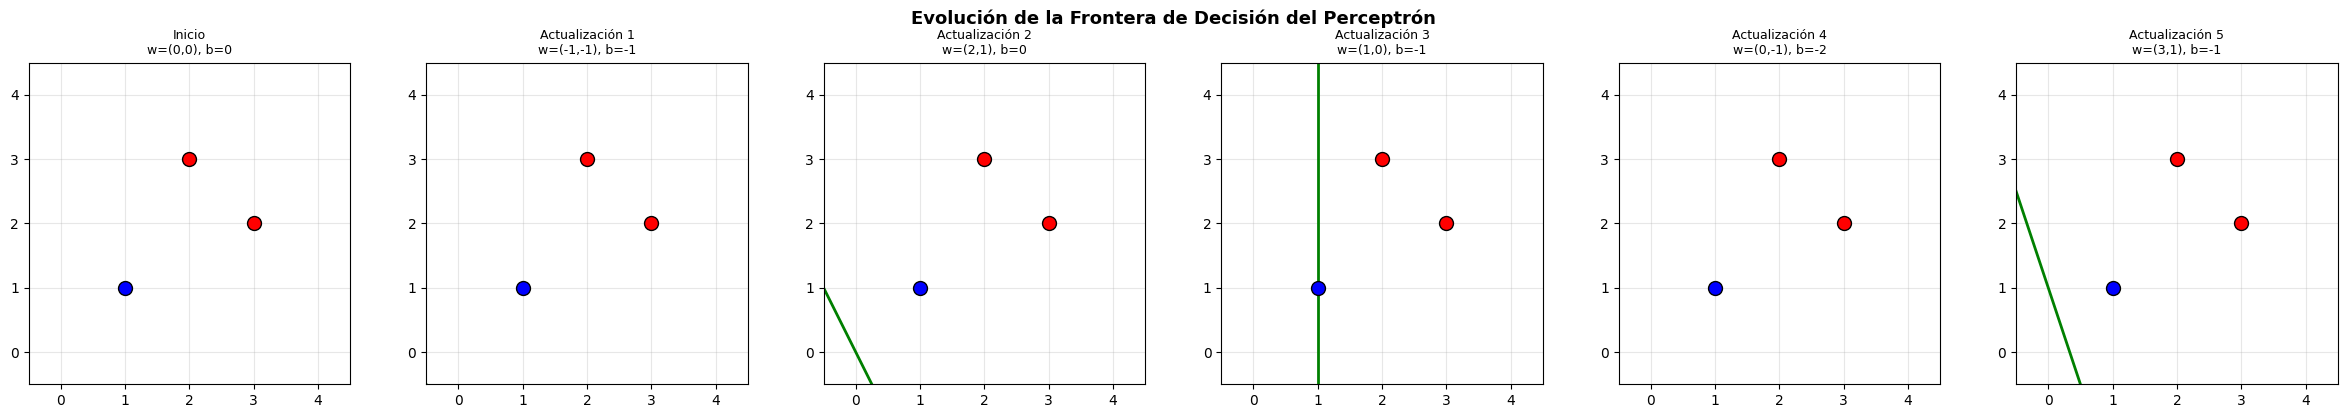

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Visualizar la evolución de la frontera de decisión durante el entrenamiento
X = np.array([[2, 3], [1, 1], [3, 2]])
y = np.array([1, 0, 1])

w = np.array([0.0, 0.0])
b = 0.0
lr = 1.0
step_func = lambda z: 1 if z >= 0 else 0

# Almacenar estados de los pesos
weight_history = [(w.copy(), b)]

for epoch in range(10):
    errors = 0
    for x_i, y_i in zip(X, y):
        z = np.dot(w, x_i) + b
        y_hat = step_func(z)
        error = y_i - y_hat
        if error != 0:
            w = w + lr * error * x_i
            b = b + lr * error
            weight_history.append((w.copy(), b))
            errors += 1
    if errors == 0:
        break

# Graficar evolución
n_steps = min(len(weight_history), 6)
fig, axes = plt.subplots(1, n_steps, figsize=(4*n_steps, 4))
if n_steps == 1:
    axes = [axes]

x_plot = np.linspace(-0.5, 4.5, 100)

for idx, ax in enumerate(axes):
    w_i, b_i = weight_history[idx]

    ax.scatter(X[y==0][:,0], X[y==0][:,1], c='blue', s=100, edgecolors='k', zorder=5, label='Clase 0')
    ax.scatter(X[y==1][:,0], X[y==1][:,1], c='red', s=100, edgecolors='k', zorder=5, label='Clase 1')

    if w_i[1] != 0:
        y_plot = (-w_i[0] * x_plot - b_i) / w_i[1]
        ax.plot(x_plot, y_plot, 'g-', lw=2)
    elif w_i[0] != 0:
        x_boundary = -b_i / w_i[0]
        ax.axvline(x=x_boundary, color='g', lw=2)

    title = 'Inicio' if idx == 0 else f'Actualización {idx}'
    ax.set_title(f'{title}\nw=({w_i[0]:.0f},{w_i[1]:.0f}), b={b_i:.0f}', fontsize=9)
    ax.set_xlim(-0.5, 4.5)
    ax.set_ylim(-0.5, 4.5)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

plt.suptitle('Evolución de la Frontera de Decisión del Perceptrón', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Implementación con Código

### Funciones

In [ ]:
import numpy as np

def unit_step(z):
    """Función escalón unitario (activación del Perceptrón)"""
    return np.where(z >= 0, 1, 0)

def perceptron_fit(X, y, learning_rate=0.01, n_iters=1000):
    """Entrena un Perceptrón y retorna los pesos y bias"""
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0.0

    # Asegurar que las etiquetas sean 0 o 1
    y_ = np.array([1 if yi > 0 else 0 for yi in y])

    for _ in range(n_iters):
        for idx, x_i in enumerate(X):
            z = np.dot(x_i, weights) + bias
            y_hat = unit_step(z)

            # Regla de actualización del Perceptrón
            update = learning_rate * (y_[idx] - y_hat)
            weights += update * x_i
            bias += update

    return weights, bias

def perceptron_predict(X, weights, bias):
    """Predice usando el Perceptrón entrenado"""
    z = np.dot(X, weights) + bias
    return unit_step(z)

def accuracy(y_true, y_pred):
    """Calcula la proporción de predicciones correctas"""
    return np.sum(y_true == y_pred) / len(y_true)

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
import numpy as np

# Generar datos linealmente separables
X, y = datasets.make_blobs(
    n_samples=150, n_features=2, centers=2, cluster_std=1.05, random_state=2
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

# Entrenar
weights, bias = perceptron_fit(X_train, y_train, learning_rate=0.01, n_iters=1000)

# Predecir
predictions = perceptron_predict(X_test, weights, bias)
acc = accuracy(y_test, predictions)
print(f"Perceptrón (funciones) accuracy: {acc:.4f}")
print(f"Pesos: w = {weights}")
print(f"Bias: b = {bias:.4f}")

Perceptrón (funciones) accuracy: 1.0000
Pesos: w = [0.03534528 0.03089668]
Bias: b = 0.1300


### Clase

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


class Perceptron:
    def __init__(self, learning_rate=0.01, n_iters=1000):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.bias = None
        self.errors_per_epoch = []  # Para rastrear el progreso

    def _unit_step_func(self, z):
        """Función escalón unitario"""
        return np.where(z >= 0, 1, 0)

    def fit(self, X, y):
        """Entrena el Perceptrón con los datos de entrenamiento"""
        n_samples, n_features = X.shape

        # Inicializar pesos en cero
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.errors_per_epoch = []

        # Asegurar que las etiquetas sean 0 o 1
        y_ = np.array([1 if i > 0 else 0 for i in y])

        for epoch in range(self.n_iters):
            errors = 0
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = self._unit_step_func(linear_output)

                # Regla de actualización del Perceptrón
                update = self.lr * (y_[idx] - y_predicted)
                self.weights += update * x_i
                self.bias += update

                if update != 0:
                    errors += 1

            self.errors_per_epoch.append(errors)

            # Convergencia temprana
            if errors == 0:
                print(f"Convergencia alcanzada en la época {epoch + 1}")
                break

    def predict(self, X):
        """Predice las clases para los datos de entrada"""
        linear_output = np.dot(X, self.weights) + self.bias
        return self._unit_step_func(linear_output)

    def score(self, X, y):
        """Calcula la accuracy del modelo"""
        predictions = self.predict(X)
        return np.sum(predictions == y) / len(y)

    def plot_errors(self):
        """Grafica el número de errores por época"""
        plt.figure(figsize=(10, 5))
        plt.plot(range(1, len(self.errors_per_epoch) + 1), self.errors_per_epoch,
                 marker='o', color='#e74c3c', linewidth=2, markersize=4)
        plt.xlabel('Época', fontsize=12)
        plt.ylabel('Número de errores', fontsize=12)
        plt.title('Convergencia del Perceptrón', fontsize=13)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def plot_decision_boundary(self, X, y, title="Frontera de decisión del Perceptrón"):
        """Grafica la frontera de decisión (solo para datos 2D)"""
        fig, ax = plt.subplots(1, 1, figsize=(8, 6))

        # Crear malla
        cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
        cmap_bold = ListedColormap(['#FF0000', '#0000FF'])

        h = 0.1
        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                             np.arange(y_min, y_max, h))

        Z = self.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolors='k', s=60)

        # Dibujar la frontera de decisión como línea
        if self.weights[1] != 0:
            x_boundary = np.array([x_min, x_max])
            y_boundary = (-self.weights[0] * x_boundary - self.bias) / self.weights[1]
            ax.plot(x_boundary, y_boundary, 'k-', linewidth=2, label='Frontera de decisión')
            ax.legend()

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel('$x_1$', fontsize=12)
        ax.set_ylabel('$x_2$', fontsize=12)
        ax.set_title(title, fontsize=13)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Generar datos linealmente separables
X, y = datasets.make_blobs(
    n_samples=150, n_features=2, centers=2, cluster_std=1.05, random_state=2
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

# Crear y entrenar
model = Perceptron(learning_rate=0.01, n_iters=1000)
model.fit(X_train, y_train)

# Evaluar
train_acc = model.score(X_train, y_train)
test_acc = model.score(X_test, y_test)
print(f"Accuracy en entrenamiento: {train_acc:.4f}")
print(f"Accuracy en prueba: {test_acc:.4f}")
print(f"Pesos: {model.weights}")
print(f"Bias: {model.bias:.4f}")

Convergencia alcanzada en la época 3
Accuracy en entrenamiento: 1.0000
Accuracy en prueba: 1.0000
Pesos: [0.03534528 0.03089668]
Bias: 0.1300


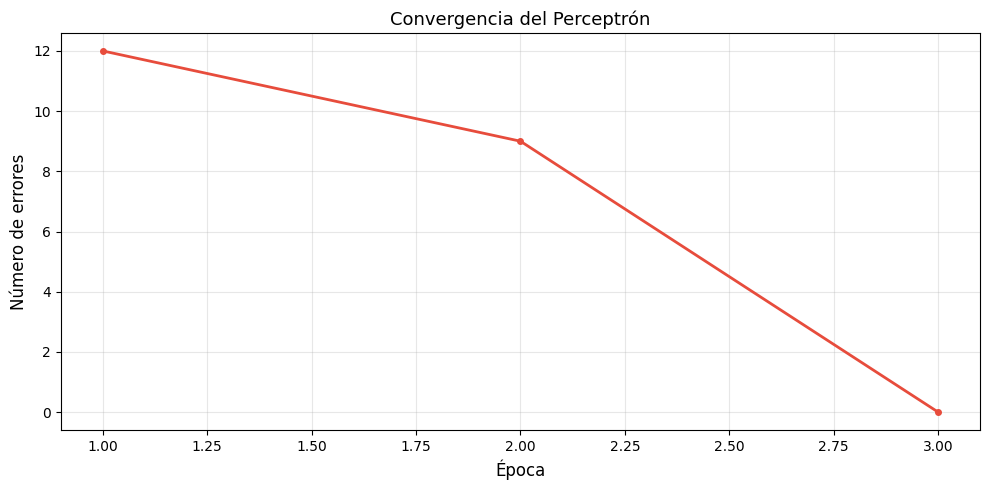

In [ ]:
# Visualizar convergencia
model.plot_errors()

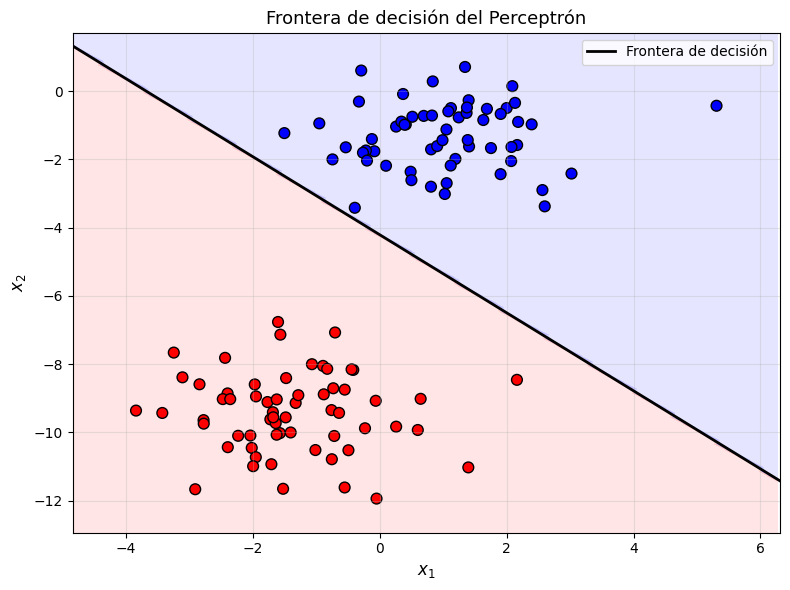

In [ ]:
# Visualizar frontera de decisión
model.plot_decision_boundary(X_train, y_train)

Convergencia alcanzada en la época 3
Convergencia alcanzada en la época 3
Convergencia alcanzada en la época 3


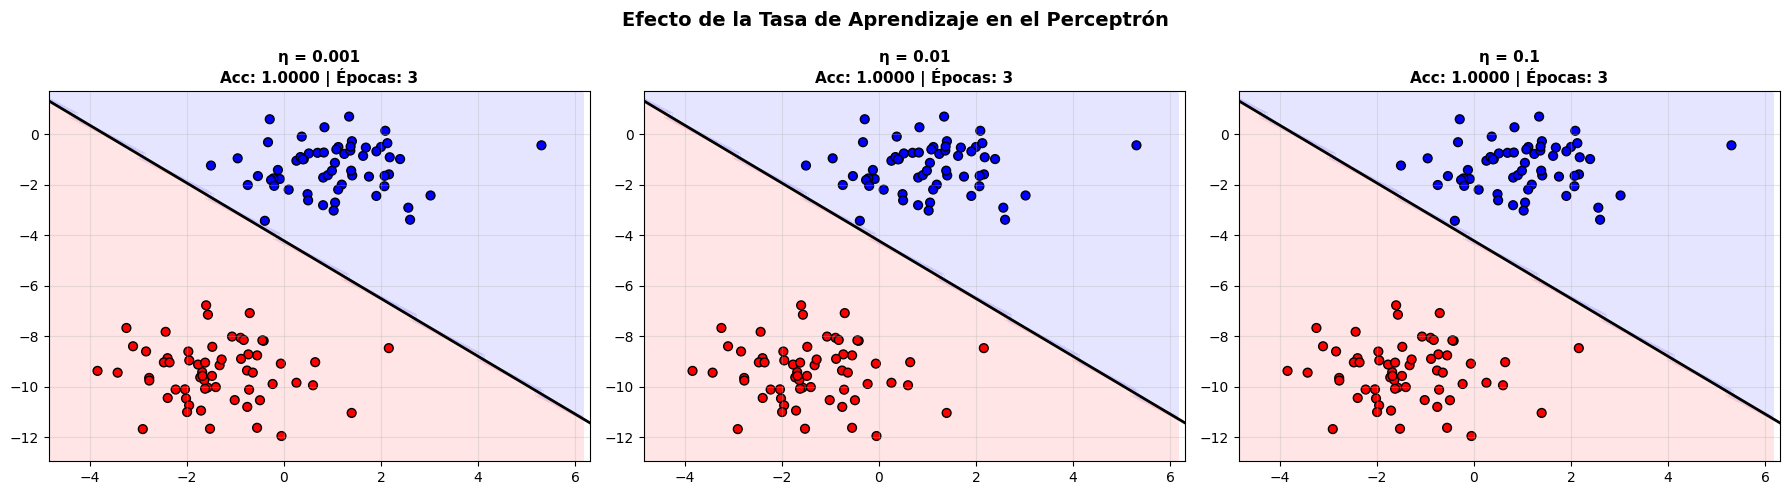

In [ ]:
# Comparar diferentes tasas de aprendizaje
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

learning_rates = [0.001, 0.01, 0.1]
cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#0000FF'])

for ax, lr_val in zip(axes, learning_rates):
    p = Perceptron(learning_rate=lr_val, n_iters=100)
    p.fit(X_train, y_train)
    acc = p.score(X_test, y_test)
    n_epochs = len(p.errors_per_epoch)

    # Malla
    h = 0.2
    x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
    y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = p.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap_bold, edgecolors='k', s=40)

    if p.weights[1] != 0:
        x_b = np.array([x_min, x_max])
        y_b = (-p.weights[0] * x_b - p.bias) / p.weights[1]
        ax.plot(x_b, y_b, 'k-', lw=2)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(f'η = {lr_val}\nAcc: {acc:.4f} | Épocas: {n_epochs}', fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.suptitle('Efecto de la Tasa de Aprendizaje en el Perceptrón', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Demostración: El Perceptrón NO puede resolver XOR
print("="*50)

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

p_xor = Perceptron(learning_rate=0.1, n_iters=100)
p_xor.fit(X_xor, y_xor)

predictions_xor = p_xor.predict(X_xor)
acc_xor = p_xor.score(X_xor, y_xor)

print(f"\nAccuracy en XOR: {acc_xor:.4f}")
print("\nPredicciones vs Real:")
for x_i, y_true, y_pred in zip(X_xor, y_xor, predictions_xor):
    status = '✓' if y_true == y_pred else '✗'
    print(f"  x={x_i} → Predicho: {y_pred}, Real: {y_true} {status}")

print(f"\nEl Perceptrón NUNCA converge en XOR (errores por época oscilan).")
print(f"Últimos 5 errores por época: {p_xor.errors_per_epoch[-5:]}")


Accuracy en XOR: 0.5000

Predicciones vs Real:
  x=[0 0] → Predicho: 1, Real: 0 ✗
  x=[0 1] → Predicho: 1, Real: 1 ✓
  x=[1 0] → Predicho: 0, Real: 1 ✗
  x=[1 1] → Predicho: 0, Real: 0 ✓

El Perceptrón NUNCA converge en XOR (errores por época oscilan).
Últimos 5 errores por época: [4, 4, 4, 4, 4]


Convergencia alcanzada en la época 3


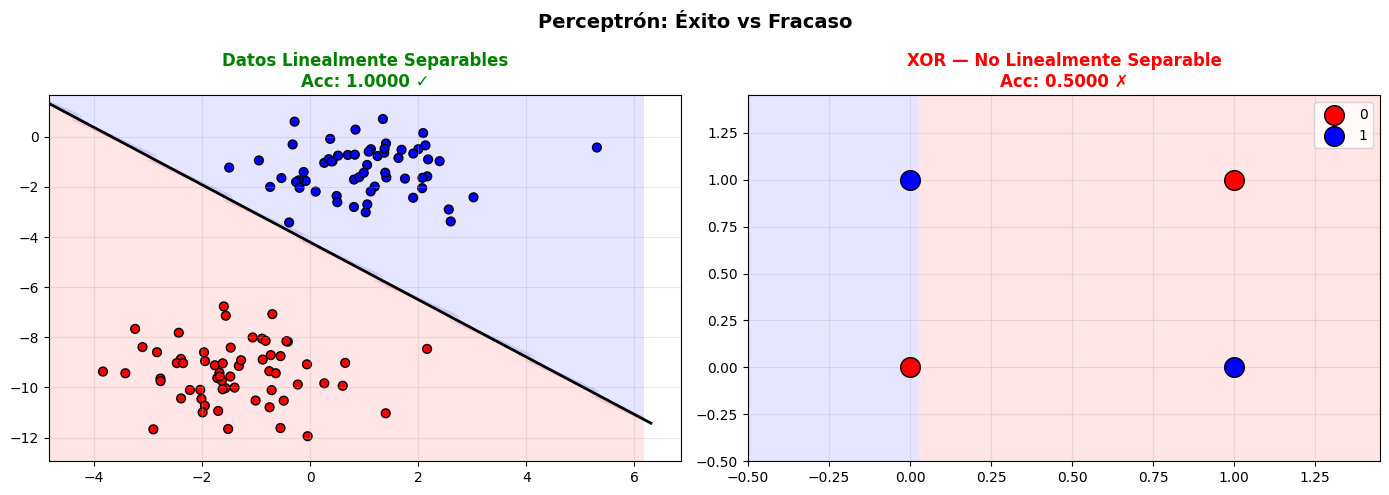

In [ ]:
# Visualizar: Perceptrón en datos linealmente separables vs XOR
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Datos separables
p_sep = Perceptron(learning_rate=0.01, n_iters=1000)
p_sep.fit(X_train, y_train)

h = 0.2
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = p_sep.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

axes[0].contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
axes[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap_bold, edgecolors='k', s=40)
if p_sep.weights[1] != 0:
    x_b = np.array([x_min, x_max])
    y_b = (-p_sep.weights[0] * x_b - p_sep.bias) / p_sep.weights[1]
    axes[0].plot(x_b, y_b, 'k-', lw=2)
axes[0].set_title(f'Datos Linealmente Separables\nAcc: {p_sep.score(X_train, y_train):.4f} ✓',
                  fontsize=12, fontweight='bold', color='green')
axes[0].grid(True, alpha=0.3)

# XOR
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
p_xor2 = Perceptron(learning_rate=0.1, n_iters=100)
p_xor2.fit(X_xor, y_xor)

h2 = 0.05
xx2, yy2 = np.meshgrid(np.arange(-0.5, 1.5, h2), np.arange(-0.5, 1.5, h2))
Z2 = p_xor2.predict(np.c_[xx2.ravel(), yy2.ravel()]).reshape(xx2.shape)

axes[1].contourf(xx2, yy2, Z2, alpha=0.3, cmap=cmap_light)
axes[1].scatter(X_xor[y_xor==0][:, 0], X_xor[y_xor==0][:, 1], c='red', s=200, edgecolors='k', zorder=5, label='0')
axes[1].scatter(X_xor[y_xor==1][:, 0], X_xor[y_xor==1][:, 1], c='blue', s=200, edgecolors='k', zorder=5, label='1')
axes[1].set_title(f'XOR — No Linealmente Separable\nAcc: {p_xor2.score(X_xor, y_xor):.4f} ✗',
                  fontsize=12, fontweight='bold', color='red')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Perceptrón: Éxito vs Fracaso', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Resumen: Perceptrón en el contexto de las Redes Neuronales
print("=" * 70)
print("RESUMEN: EL PERCEPTRÓN EN EL CONTEXTO DE LAS REDES NEURONALES")
print("=" * 70)
print()
print("┌─────────────────────────────────────────────────────────────────┐")
print("│ Perceptrón                                                      │")
print("│   • Es la red neuronal más simple: UNA sola neurona             │")
print("│   • Función de activación: escalón unitario (step function)     │")
print("│   • Solo puede resolver problemas linealmente separables        │")
print("│   • Regla de aprendizaje: corrección de errores                 │")
print("│   • Garantía de convergencia si datos son separables            │")
print("├─────────────────────────────────────────────────────────────────┤")
print("│ Limitaciones → Motivación para redes más complejas              │")
print("│   • No resuelve XOR ni problemas no lineales                    │")
print("│   • Solución: Perceptrón Multicapa (MLP) + Backpropagation      │")
print("│   • Múltiples neuronas + capas ocultas = fronteras no lineales  │")
print("│   • Con suficientes neuronas → aproximador universal            │")
print("├─────────────────────────────────────────────────────────────────┤")
print("│ Comparación con otros modelos lineales                          │")
print("│   • Regresión Logística: minimiza log-loss (diferenciable)      │")
print("│   • SVM: maximiza margen (optimización convexa)                 │")
print("│   • Perceptrón: corrección de errores (más simple)              │")
print("│   • Los tres encuentran hiperplanos, pero con diferentes        │")
print("│     criterios de optimización                                   │")
print("└─────────────────────────────────────────────────────────────────┘")

RESUMEN: EL PERCEPTRÓN EN EL CONTEXTO DE LAS REDES NEURONALES

┌─────────────────────────────────────────────────────────────────┐
│ Perceptrón                                                      │
│   • Es la red neuronal más simple: UNA sola neurona             │
│   • Función de activación: escalón unitario (step function)     │
│   • Solo puede resolver problemas linealmente separables        │
│   • Regla de aprendizaje: corrección de errores                 │
│   • Garantía de convergencia si datos son separables            │
├─────────────────────────────────────────────────────────────────┤
│ Limitaciones → Motivación para redes más complejas              │
│   • No resuelve XOR ni problemas no lineales                    │
│   • Solución: Perceptrón Multicapa (MLP) + Backpropagation      │
│   • Múltiples neuronas + capas ocultas = fronteras no lineales  │
│   • Con suficientes neuronas → aproximador universal            │
├────────────────────────────────────────────────────